# notebook: remove minor braided steams from NWM hydrofabric

- one-time processing
    - input:
        - nwm hydrofabric: flowline 
        - nwm hydrofabric: catchment
    - output:
        - minor stream COMID table
- actions in FIM3 workflow:
    - remove minor stream features from nwm flowline subset
    - remove minor stream catchment polygon from nwm catchment subset. `add_crosswalk.py` uses the rasterized catchment tif for FR, so as long as I removed minor braided stream catchments in catchment polygon data, we are safe.

- TODOs
    - In FIM3, for MS, it does not use catchment raster. instead, it uses so called ` stream segment midpoint method` which uses national-level catchment polygon data as input. so we will handle that in FIM4
    - we rely on the "to" field in nwm flows data to get the main stream, so we cannot handle the case in which a headwater point splits into two flows, and the two then merge at a point.

In [1]:
import os, sys, time
import numpy as np
# import numpy.ma as ma
import matplotlib.pyplot as plt

import pickle
import pandas as pd
import shapely
import shapely.geometry
import shapely.errors
import shapely.ops
import fiona
import fiona.crs
# import rasterio
# import rasterio.mask
# import rasterio.features
# import rasterio.windows
# import affine
# import geopandas as gpd

# import rtree
# import math

In [39]:
shapely.__version__

'1.7.0'

In [2]:
# input: national
f_flow = '/home/yxl/test/fim3/inputs/nwm_hydrofabric/nwm_flows.gpkg'
lyrname_flow = 'nwm_streams'
f_catch = '/home/yxl/test/fim3/inputs/nwm_hydrofabric/nwm_catchments.gpkg'
lyrname_catch = 'nwm_catchments'

In [3]:
# input: huc8 test
f_flow = '/dev/shm/fim3/12030201/nwm_subset_streams.gpkg'
lyrname_flow = 'nwm_subset_streams'
f_catch = '/dev/shm/fim3/12030201/nwm_catchments_proj_subset.gpkg'
lyrname_catch = 'nwm_catchments_proj_subset'

In [3]:
%%time
# build lookup tables
flow = fiona.open(f_flow, mode='r', layer=lyrname_flow)
flow2downstream = {} # COMID to main downstream COMID mapping
start2flows = {} # start point to flow COMID mapping. if a point has 2+ flows, they are braided
flow2ends = {} # flow COMID to start point mapping
for feat in flow:
    pt_start = feat['geometry']['coordinates'][0]
    pt_end = feat['geometry']['coordinates'][-1]
    comid = feat['properties']['ID']
    to = feat['properties']['to'] # to=0 if no downstream
    if to > 0:
        flow2downstream[comid] = to
    if not pt_start in start2flows:
        start2flows[pt_start] = [comid]
    else:
        start2flows[pt_start].append(comid)
    flow2ends[comid] = (pt_start, pt_end)
flow.close()

CPU times: user 41.4 s, sys: 2.5 s, total: 43.9 s
Wall time: 44.6 s


In [4]:
%%time
# calc braided streams stat
count = 0
braided = 0
for k, v in start2flows.items():
    if len(v) > 1:
        count += 1
        braided += len(v)

to_notin_net = 0
to_notin_net_braided = 0
for comid, to in flow2downstream.items():
    if not to in flow2ends: # major downstream is out of network
        to_notin_net += 1
        start = flow2ends[comid][1] # use flow's end pt as downstream's start pt
        if start in start2flows and len(start2flows[start]) > 1: # major downstream out of network, and part of braided
            to_notin_net_braided += 1
print('===streams stat===')
print('total:\t', len(flow2ends))
print('with_downstreams:\t', len(flow2downstream))
print('with_braided_downstreams_in_net:\t', count)
print('braided_streams:\t', braided)
print('major_downstreams_out_of_network:\t', to_notin_net)
print('major_downstreams_out_of_network_and_braided:\t', to_notin_net_braided)

===streams stat===
total:	 2804388
with_downstreams:	 2789546
with_braided_downstreams_in_net:	 66699
braided_streams:	 134067
major_downstreams_out_of_network:	 0
major_downstreams_out_of_network_and_braided:	 0
CPU times: user 1.15 s, sys: 1.91 ms, total: 1.15 s
Wall time: 1.15 s


In [5]:
%%time
# find minor braided streams
minor_braided = {} # use dict to avoid duplicate entries that are possible if w/ two up flows and two down flows join at a single point, case: huc8 12030201; two down flows: 4133143, 4133187
for comid in flow2ends: # foreach stream
    if comid in flow2downstream: # if it has downstreams
        to = flow2downstream[comid]
        if to in flow2ends: # if downstream is in the network
            pt_start = flow2ends[to][0]
        else: # use flow's end pt as downstream's start pt. note that braided streams in this scenario may not be complete; we make best effort
            pt_start = flow2ends[comid][1]
            #print('downstream_out_of_net:', comid, '->', to)
        if pt_start in start2flows and len(start2flows[pt_start]) > 1: # braided
            for i in start2flows[pt_start]: # note: to may not on this list, but it is the major channel
                if i != to:
                    if not i in minor_braided:
                        minor_braided[i] = to # add a uniq row to table
                    elif minor_braided[i] != to:
                        print('ERROR in processing comid', comid, ': one minor stream', i, 'has two main streams', minor_braided[i], to)
minor_braided_list = [ [k, v] for k, v in minor_braided.items() ]

ERROR in processing comid 3193484 : one minor stream 3193484 has two main streams 3193482 3193504
ERROR in processing comid 3193482 : one minor stream 3193484 has two main streams 3193482 3193504
ERROR in processing comid 18329760 : one minor stream 18329764 has two main streams 18331572 18329762
ERROR in processing comid 18328894 : one minor stream 18329052 has two main streams 18329038 18328892
ERROR in processing comid 18328598 : one minor stream 18331476 has two main streams 18328598 18328624
CPU times: user 2.84 s, sys: 9.02 ms, total: 2.85 s
Wall time: 2.85 s


In [11]:
# save dict as pickle file, list as numpy array and csv
#f_o = '/home/yxl/test/fim3/braided_streams/braided_streams_lookup_minor2main'
f_o = '/tmp/braided_streams_lookup_minor2main'
with open(f_o + '.pickle', 'wb') as f:
    pickle.dump(minor_braided, f)
odata = np.array(minor_braided_list, dtype=np.int64)
np.save(f_o + '.npy', odata, allow_pickle=False)
o = pd.DataFrame(data=odata,
                columns=['minor_stream_id', 'main_stream_id']
                )
o.to_csv(f_o + '.csv', index=False)

## climate project: test getting max streamflow for braided streams

In [5]:
f_o = '/srv/test/cahaba/ornl/braided_streams/braided_streams_lookup_minor2main'
lookup = np.load(f_o + '.npy')
lookup.shape

(66128, 2)

In [6]:
with open(f_o+'.pickle', 'rb') as f:
    lookup = pickle.load(f)
len(lookup)

66128

In [2]:
fcfile="/home/yxl/test/climate/data/flood-freq/02070005/GEV_1980_2019_plhv_constraint.txt"
rps=['MRI-ESM2-0_plhv_25', 'MRI-ESM2-0_plhv_50', 'MRI-ESM2-0_plhv_100', 'MRI-ESM2-0_plhv_200', 'CNRM-ESM2-1_plhv_25', 'CNRM-ESM2-1_plhv_50', 'CNRM-ESM2-1_plhv_100', 'CNRM-ESM2-1_plhv_200', 'MPI-ESM1-2-HR_plhv_25', 'MPI-ESM1-2-HR_plhv_50', 'MPI-ESM1-2-HR_plhv_100', 'MPI-ESM1-2-HR_plhv_200', 'BCC-CSM2-MR_plhv_25', 'BCC-CSM2-MR_plhv_50', 'BCC-CSM2-MR_plhv_100', 'BCC-CSM2-MR_plhv_200', 'ACCESS-CM2_plhv_25', 'ACCESS-CM2_plhv_50', 'ACCESS-CM2_plhv_100', 'ACCESS-CM2_plhv_200', 'NorESM2-MM_plhv_25', 'NorESM2-MM_plhv_50', 'NorESM2-MM_plhv_100', 'NorESM2-MM_plhv_200']
d_ffreq = pd.read_csv(fcfile, usecols=['COMID']+rps)
comids_f = np.unique(d_ffreq['COMID'])

In [46]:
d_ffreq.head()

,COMID,MRI-ESM2-0_plhv_25,MRI-ESM2-0_plhv_50,MRI-ESM2-0_plhv_100,MRI-ESM2-0_plhv_200,CNRM-ESM2-1_plhv_25,CNRM-ESM2-1_plhv_50,CNRM-ESM2-1_plhv_100,CNRM-ESM2-1_plhv_200,MPI-ESM1-2-HR_plhv_25,...,BCC-CSM2-MR_plhv_100,BCC-CSM2-MR_plhv_200,ACCESS-CM2_plhv_25,ACCESS-CM2_plhv_50,ACCESS-CM2_plhv_100,ACCESS-CM2_plhv_200,NorESM2-MM_plhv_25,NorESM2-MM_plhv_50,NorESM2-MM_plhv_100,NorESM2-MM_plhv_200
0,5908907,0.4803,0.5398,0.5987,0.6573,0.4729,0.5408,0.6115,0.6851,0.4932,...,0.5800,0.6276,0.5265,0.6166,0.7139,0.8194,0.5426,0.6555,0.7861,0.9375
1,5906835,5.6552,6.7253,7.9025,9.2016,6.6187,8.5641,11.0070,14.0822,5.9511,...,10.4042,12.6603,6.7980,8.8007,11.3206,14.4992,6.1140,7.8959,10.1754,13.0987
2,5908799,0.0522,0.0918,0.1615,0.2841,0.0522,0.0910,0.1586,0.2766,0.0357,...,0.1586,0.2810,0.0427,0.0748,0.1314,0.2316,0.0432,0.0745,0.1292,0.2246
3,5909063,3.7270,4.3411,4.9967,5.6987,3.4059,4.0431,4.7515,5.5416,4.4908,...,5.4661,6.3770,4.0852,5.0341,6.1443,7.4471,3.5040,4.0539,4.6361,5.2546
4,5907351,0.1712,0.1929,0.2148,0.2371,0.1726,0.1980,0.2247,0.2529,0.1664,...,0.1787,0.1884,0.1899,0.2223,0.2575,0.2958,0.2020,0.2473,0.3014,0.3659


In [3]:
l = [5908765, 5908763, 5908307, 5908739, 5908761, 5908747, 5908743, 5908737, 5908741, 5908283, 5908730, 5908729]
d_ffreq.loc[d_ffreq['COMID'].isin(l), ['COMID','MRI-ESM2-0_plhv_25']]

,COMID,MRI-ESM2-0_plhv_25
63,5908741,0.0000
239,5908763,0.0000
279,5908283,0.2130
305,5908307,0.4745
480,5908739,0.4793
809,5908765,221.2970
810,5908761,409.6683
811,5908747,409.6683
812,5908743,409.6683
813,5908737,409.6683


In [28]:
l = [5909183, 5908981, 5908979, 5909159]
d_ffreq.loc[d_ffreq['COMID'].isin(l), ['COMID','MRI-ESM2-0_plhv_25']]

,COMID,MRI-ESM2-0_plhv_25
73,5909159,4.3634
613,5909183,9.8260
643,5908981,9.8535
672,5908979,11.8988


In [47]:
d_ffreq.dtypes

COMID                       int64
MRI-ESM2-0_plhv_25        float64
MRI-ESM2-0_plhv_50        float64
MRI-ESM2-0_plhv_100       float64
MRI-ESM2-0_plhv_200       float64
CNRM-ESM2-1_plhv_25       float64
CNRM-ESM2-1_plhv_50       float64
CNRM-ESM2-1_plhv_100      float64
CNRM-ESM2-1_plhv_200      float64
MPI-ESM1-2-HR_plhv_25     float64
MPI-ESM1-2-HR_plhv_50     float64
MPI-ESM1-2-HR_plhv_100    float64
MPI-ESM1-2-HR_plhv_200    float64
BCC-CSM2-MR_plhv_25       float64
BCC-CSM2-MR_plhv_50       float64
BCC-CSM2-MR_plhv_100      float64
BCC-CSM2-MR_plhv_200      float64
ACCESS-CM2_plhv_25        float64
ACCESS-CM2_plhv_50        float64
ACCESS-CM2_plhv_100       float64
ACCESS-CM2_plhv_200       float64
NorESM2-MM_plhv_25        float64
NorESM2-MM_plhv_50        float64
NorESM2-MM_plhv_100       float64
NorESM2-MM_plhv_200       float64
dtype: object

In [48]:
comids_f.shape, comids_f[5], comids_f[50], comids_f[100], comids_f[500]

((891,), 5906805, 5907067, 5907167, 5908619)

In [7]:
# reformat to comid->[all braided comids associated with the comid]
# regardless comid is minor or main
main2minors = {}
comids_f_set = set(comids_f)
for minor, main in lookup.items():
    if not (minor in comids_f_set and main in comids_f_set):
        continue
    if not main in main2minors:
        main2minors[main] = [minor]
    else:
        main2minors[main].append(minor)

In [8]:
main2minors

{5908657: [5908649],
 5908743: [5908741],
 5908761: [5908763],
 5908385: [5908383],
 5908489: [5908491],
 5908979: [5909159],
 5909683: [5909685],
 5909693: [5909691],
 5909971: [5909979],
 5907315: [5907317]}

In [9]:
braided_list = [ [k] + v for k,v in main2minors.items() ]
braided_list

[[5908657, 5908649],
 [5908743, 5908741],
 [5908761, 5908763],
 [5908385, 5908383],
 [5908489, 5908491],
 [5908979, 5909159],
 [5909683, 5909685],
 [5909693, 5909691],
 [5909971, 5909979],
 [5907315, 5907317]]

In [19]:
rps = ['MRI-ESM2-0_plhv_25', 'MRI-ESM2-0_plhv_50', 'CNRM-ESM2-1_plhv_200', 'MPI-ESM1-2-HR_plhv_25']

In [20]:
d_ffreq.loc[d_ffreq['COMID'].isin(braided_list[2]), rps]

,MRI-ESM2-0_plhv_25,MRI-ESM2-0_plhv_50,CNRM-ESM2-1_plhv_200,MPI-ESM1-2-HR_plhv_25
239,0.0000,485.9789,505.3555,471.1642
810,409.6683,485.9789,505.3555,471.1642


In [21]:
num_rows = d_ffreq.loc[d_ffreq['COMID'].isin(braided_list[2]), rps].shape[0]
num_rows

2

In [22]:
col_max = d_ffreq.loc[d_ffreq['COMID'].isin(braided_list[2]), rps].max()
print(type(col_max))
col_max.head()

<class 'pandas.core.series.Series'>


MRI-ESM2-0_plhv_25       409.6683
MRI-ESM2-0_plhv_50       485.9789
CNRM-ESM2-1_plhv_200     505.3555
MPI-ESM1-2-HR_plhv_25    471.1642
dtype: float64

In [23]:
new_coldata =  [ [col_max[col]] * num_rows for col in rps ]
new_coldata

[[409.6683, 409.6683],
 [485.9789, 485.9789],
 [505.3555, 505.3555],
 [471.1642, 471.1642]]

In [24]:
new_coldata = np.array(new_coldata, dtype=np.float64).transpose()
new_coldata

array([[409.6683, 485.9789, 505.3555, 471.1642],
       [409.6683, 485.9789, 505.3555, 471.1642]])

In [25]:
d_ffreq.loc[d_ffreq['COMID'].isin(braided_list[2]), rps] = new_coldata

In [26]:
d_ffreq.loc[d_ffreq['COMID'].isin(braided_list[2]), rps]

,MRI-ESM2-0_plhv_25,MRI-ESM2-0_plhv_50,CNRM-ESM2-1_plhv_200,MPI-ESM1-2-HR_plhv_25
239,409.6683,485.9789,505.3555,471.1642
810,409.6683,485.9789,505.3555,471.1642


In [67]:
# output braided area into GIS
braided_comids = [ comids for comid_list in braided_list for comids in comid_list ]
braided_comids = set(braided_comids)
f_streams = '/dev/shm/climate/02070005/nwm_subset_streams.gpkg'
of_streams = '/dev/shm/climate/test/braided/nwm_braided_streams.gpkg'
streams = fiona.open(f_streams, mode='r')
with fiona.open(of_streams, 
               mode = 'w',
               layer='braided_streams',
               driver = streams.driver,
               crs = streams.crs,
               schema = streams.schema) as of:
    for feat in streams:
        comid = feat['properties']['ID'] # ['feature_id']
        if comid in braided_comids:
            of.write(feat)
streams.close()

In [27]:
l = [5908765, 5908763, 5908307, 5908739, 5908761, 5908747, 5908743, 5908737, 5908741, 5908283, 5908730, 5908729]
d_ffreq.loc[d_ffreq['COMID'].isin(l), ['COMID','MRI-ESM2-0_plhv_25']]

,COMID,MRI-ESM2-0_plhv_25
63,5908741,0.0000
239,5908763,409.6683
279,5908283,0.2130
305,5908307,0.4745
480,5908739,0.4793
809,5908765,221.2970
810,5908761,409.6683
811,5908747,409.6683
812,5908743,409.6683
813,5908737,409.6683


## data issue: 3193504
COMID 3193504's linestring points are ordered from downstream to upstream, which is the opposite of most COMIDs. 

In [9]:
start2flows[flow2ends[3193504][0]]

[3193484, 3193482, 3193504]

In [10]:
flow2ends[3193504]

((-1197344.9975908264, 2181739.418716644),
 (-1197217.8100766873, 2180914.0946792727))

In [11]:
flow2ends[3193484]

((-1197344.9975908264, 2181739.418716644),
 (-1197497.3097842168, 2182073.887158525))

In [12]:
flow2ends[3193482]

((-1197344.9975908264, 2181739.418716644),
 (-1197497.3097842168, 2182073.887158525))

In [60]:
odata.shape

(24, 2)

In [61]:
odata

array([[1453445, 1453425],
       [1456145, 1456141],
       [1456095, 1456097],
       [1456093, 1456085],
       [1455983, 1455993],
       [1455975, 1455977],
       [1457215, 1457213],
       [1456001, 1456003],
       [4133357, 4133355],
       [4133203, 4133197],
       [1454871, 1454867],
       [4133187, 4133143],
       [4133101, 4133093],
       [1459819, 1455471],
       [1454941, 1454933],
       [1454873, 1454881],
       [1454847, 1454845],
       [1454951, 1454939],
       [1454843, 4133165],
       [1454837, 4133163],
       [1453685, 1453199],
       [1453013, 1453019],
       [1451427, 1451429],
       [1452853, 1452875]])

In [52]:
flow2ends[4133187]

((-15261.663827683738, 988164.9992365949),
 (-9954.448880047548, 987080.7659988861))

In [53]:
start2flows[flow2ends[4133187][0]]

[4133187, 4133143]

In [54]:
flow2ends[4133143]

((-15261.663827683738, 988164.9992365949),
 (-12454.881565840007, 987829.2140360699))

In [55]:
start2flows[flow2ends[4133143][0]]

[4133187, 4133143]

# use the braided stream lookup table to remove minor streams and their catchments in subsetted nwm hydrofabric

In [23]:
def remove_minor_streams_and_catch(f_lookup, f_fabric_streams, lyr_streams, f_fabric_catch, lyr_catch, of_fabric_streams, of_fabric_catch):
    with open(f_lookup, 'rb') as f:
        lookup = pickle.load(f)
        if len(lookup) == 0:
            print('ERROR remove_minor_streams_and_catch:', 'lookup table has not data -', f_lookup)
            return
        
        streams = fiona.open(f_fabric_streams, mode='r', layer=lyr_streams)
        n_streams = len(streams)
        o_streams = []
        for feat in streams:
            if not feat['properties']['ID'] in lookup: # keep if not a minor braided stream
                o_streams.append(feat)
        with fiona.open(of_fabric_streams, 
                       mode = 'w',
                       layer=lyr_streams,
                       driver = streams.driver,
                       crs = streams.crs,
                       schema = streams.schema) as of:
            for feat in o_streams:
                of.write(feat)
        streams.close()
        print('remove_minor_streams_and_catch: read', n_streams, 'streams', ', found', n_streams - len(o_streams), 'minor braided strems', ', wrote', len(o_streams), 'streams into output', of_fabric_streams)
        
        catch = fiona.open(f_fabric_catch, mode='r', layer=lyr_catch)
        n_catch = len(catch)
        o_catch = []
        for feat in catch:
            if not feat['properties']['ID'] in lookup: # keep if not of a minor braided stream
                o_catch.append(feat)
        with fiona.open(of_fabric_catch, 
                       mode = 'w',
                       layer=lyr_catch,
                       driver = catch.driver,
                       crs = catch.crs,
                       schema = catch.schema) as of:
            for feat in o_catch:
                of.write(feat)
        catch.close()
        print('remove_minor_streams_and_catch: read', n_catch, 'catchments', ', found', n_catch - len(o_catch), 'minor braided strems', ', wrote', len(o_catch), 'catchments into output', of_fabric_catch)

In [24]:
remove_minor_streams_and_catch('/tmp/braided_streams_lookup_minor2main.pickle', 
                               '/home/yxl/test/fim3/cache/outputs/13090002/13090002/nwm_subset_streams.gpkg', 
                               'nwm_subset_streams', 
                               '/home/yxl/test/fim3/cache/outputs/13090002/13090002/nwm_catchments_proj_subset.gpkg', 
                               'nwm_catchments_proj_subset', 
                               '/tmp/13090002_streams.gpkg', 
                               '/tmp/13090002_catch.gpkg'
                              )

remove_minor_streams_and_catch: read 498 streams , found 4 minor braided strems , wrote 494 streams into output /tmp/13090002_streams.gpkg
remove_minor_streams_and_catch: read 534 catchments , found 0 minor braided strems , wrote 534 catchments into output /tmp/13090002_catch.gpkg


In [7]:
# index catchment features using comids
h_flows = {}
for feat in catch:
    comid = feat['properties']['ID']
    if not comid in h_flows:
        h_flows[comid] = feat
    else:
        print('ERROR', 'comid', comid, 'has two features in catchment data')

In [11]:
main2minors = {}
for minor, main in lookup.items():
    if not (minor in h_flows and main in h_flows):
        continue
    if not main in main2minors:
        main2minors[main] = [minor]
    else:
        main2minors[main].append(minor)

# merge catchments as another way to improve crosswalk on braided streams

In [105]:
def merge_minor_catch(f_lookup, f_fabric_streams, lyr_streams, f_fabric_catch, lyr_catch, of_fabric_streams, of_fabric_catch):
    with open(f_lookup, 'rb') as f:
        lookup = pickle.load(f)
        if len(lookup) == 0:
            print('ERROR remove_minor_streams_and_catch:', 'lookup table has not data -', f_lookup)
            return
        
        # index catchment features using comids
        catch = fiona.open(f_fabric_catch, mode='r', layer=lyr_catch)
        n_catch = len(catch)
        h_flows = {}
        for feat in catch:
            comid = feat['properties']['ID']
            if not comid in h_flows:
                h_flows[comid] = feat
            else:
                print('ERROR', 'comid', comid, 'has two features in catchment data')

        # index minor braided streams using the main channel's comid
        main2minors = {}
        for minor, main in lookup.items():
            if not (minor in h_flows and main in h_flows):
                continue
            if not main in main2minors:
                main2minors[main] = [minor]
            else:
                main2minors[main].append(minor)
        
        def extract_polygons(geom):
            if geom.geom_type == 'Polygon':
                return [geom]
            elif geom.geom_type == 'MultiPolygon':
                return [ g for g in geom.geoms ]
            else:
                return []
        
        # foreach main braided stream, merge its catch with its minor streams' catch
        o_catch = []
        for comid, feat in h_flows.items(): # scan all catchments
            if comid in lookup: # a minor braided stream: will be merged with main, so skip
                continue
            elif comid in main2minors: # a main channel, merge with minors
                b_geoms = extract_polygons(shapely.geometry.shape(h_flows[comid]['geometry']))
                for minor in main2minors[comid]:
                    b_geoms += extract_polygons(shapely.geometry.shape(h_flows[minor]['geometry']))
                merged = shapely.geometry.MultiPolygon(b_geoms).buffer(0) # output either polygon or multipolygon
                if merged.geom_type == 'Polygon': 
                    merged = shapely.geometry.MultiPolygon([ merged ])
                # create new feature
                new_feat = {
                    'geometry': shapely.geometry.mapping(merged),
                    'properties': feat['properties']
                }
                o_catch.append(new_feat)
            else: # irrelevant, keep
                o_catch.append(feat)
        
        # save merged catchments
        with fiona.open(of_fabric_catch, 
                       mode = 'w',
                       layer=lyr_catch,
                       driver = catch.driver,
                       crs = catch.crs,
                       schema = catch.schema) as of:
            for feat in o_catch:
                of.write(feat)
        catch.close()
        print('merge_minor_catch: read', n_catch, 'catchments', ', found', n_catch - len(o_catch), 'minor braided strems', ', wrote', len(o_catch), 'catchments into output', of_fabric_catch)

In [106]:
merge_minor_catch('/home/yxl/test/fim3/braided_streams/braided_streams_lookup_minor2main.pickle', 
                               '/home/yxl/test/fim3/region6/fullfull/12030201/nwm_subset_streams.gpkg', 
                               'nwm_subset_streams', 
                               '/home/yxl/test/fim3/region6/fullfull/12030201/nwm_catchments_proj_subset.gpkg', 
                               'nwm_catchments_proj_subset', 
                               '/tmp/12030201_streams.gpkg', 
                               '/tmp/12030201_catch_merged.gpkg'
                              )

merge_minor_catch: read 1988 catchments , found 24 minor braided strems , wrote 1964 catchments into output /tmp/12030201_catch_merged.gpkg


# check FIM3 stream data before/after minor braided stream removal

In [7]:
def hash_hid2comd(f_streams):
    hid2comid = {}
    with fiona.open(f_streams, mode='r') as streams:
        for feat in streams:
            hid = feat['properties']['HydroID']
            if hid in hid2comid:
                print('ERROR HydroID has multi rows', hid)
                continue
            hid2comid[hid] = feat['properties']['feature_id']
    return hid2comid

cdir = '/home/yxl/test/fim3/braided_streams/compare'

for h in ['12090201', '12090202', '12090203', '12090204', '12090205', '12090206']:
    hid2comid_0 = hash_hid2comd(cdir + '/before/' + h + '/demDerived_reaches_split_filtered_addedAttributes_crosswalked.gpkg')
    hid2comid_1 = hash_hid2comd(cdir + '/removed/' + h + '/demDerived_reaches_split_filtered_addedAttributes_crosswalked.gpkg')
    hid2comid_2 = hash_hid2comd(cdir + '/merged/' + h + '/demDerived_reaches_split_filtered_addedAttributes_crosswalked.gpkg')

    print('HUC:', h)
    print('\t', 'HydroID,original,new_removed,new_merged')
    for k, v in hid2comid_0.items():
        v1 = hid2comid_1[k]
        v2 = hid2comid_2[k]
        if v != v1 or v != v2:
            print('\t', k, ',', v, ',', v1, ',', v2)

HUC: 12090201
	 HydroID,original,new_removed,new_merged
HUC: 12090202
	 HydroID,original,new_removed,new_merged
	 25020237 , 5761297 , 5761283 , 5761271
	 25020238 , 5761297 , 5761295 , 5761271
HUC: 12090203
	 HydroID,original,new_removed,new_merged
	 25030015 , 5765209 , 5765217 , 5765211
HUC: 12090204
	 HydroID,original,new_removed,new_merged
	 25040012 , 5771365 , 5771375 , 5771355
	 25040017 , 5771735 , 5771733 , 5771277
	 25040018 , 5771287 , 5771287 , 5771291
	 25040045 , 5771023 , 5771023 , 5771009
	 25040050 , 5771087 , 5771783 , 5771089
	 25040056 , 5771121 , 5771135 , 5771113
	 25040062 , 5771203 , 5771205 , 5771205
	 25040071 , 5771309 , 5771309 , 5771317
	 25040573 , 5772635 , 5772633 , 5772633
HUC: 12090205
	 HydroID,original,new_removed,new_merged
HUC: 12090206
	 HydroID,original,new_removed,new_merged


# create GIS data for the lookup table

In [15]:
# input: national
f_flow = '/home/yxl/test/fim3/inputs/nwm_hydrofabric/nwm_flows.gpkg'
lyrname_flow = 'nwm_streams'
f_catch = '/home/yxl/test/fim3/inputs/nwm_hydrofabric/nwm_catchments.gpkg'
lyrname_catch = 'nwm_catchments'

In [16]:
f_lookup = '/home/yxl/test/fim3/braided_streams/braided_streams_lookup_minor2main.pickle'
lookup = None
with open(f_lookup, 'rb') as f:
    lookup = pickle.load(f)

In [17]:
flows = fiona.open(f_flow, mode='r', layer=lyrname_flow)
flows.schema

{'properties': OrderedDict([('ID', 'int'),
              ('to', 'int'),
              ('order_', 'int'),
              ('Lake', 'int'),
              ('gages', 'str'),
              ('Slope', 'float'),
              ('Length', 'float'),
              ('Shape_Length', 'float'),
              ('mainstem', 'int')]),
 'geometry': 'LineString'}

In [18]:
from collections import OrderedDict # for output schema

In [19]:
oe_schema = {
    'properties': OrderedDict([
        ('ID', 'int'),
        ('to', 'int'),
        ('mainID', 'int')
    ]),
    'geometry': 'LineString'
}

In [20]:
oe_shp = fiona.open('/home/yxl/test/fim3/braided_streams/minor_braided_streams.gpkg', 'w', driver=flows.driver, crs=flows.crs, schema=oe_schema)

h_mainID = set()
for feat in flows:
    if not feat['properties']['ID'] in lookup:
        continue
    
    comid = feat['properties']['ID']
    mainID = lookup[comid]
    
    oe = {
        'geometry': feat['geometry'],
        'properties': OrderedDict([
            ('ID', comid),
            ('to', feat['properties']['to']),
            ('mainID', int(mainID)) 
        ])
    }
    oe_shp.write(oe)
    
    if not mainID in h_mainID:
        h_mainID.add(mainID)

oe_shp.close()

In [21]:
om_shp = fiona.open('/home/yxl/test/fim3/braided_streams/main_braided_streams.gpkg', 'w', driver=flows.driver, crs=flows.crs, schema=flows.schema)
for feat in flows:
    if not feat['properties']['ID'] in h_mainID:
        continue
    om_shp.write(feat)
om_shp.close()

In [13]:
s = set()
s.add(5)
s.add('5')

In [14]:
s

{'5', 5}

## test: merge catch polygons

In [4]:
f_fabric_catch = '/home/yxl/test/fim3/region6/fullfull/12030201/nwm_catchments_proj_subset.gpkg'
lyr_catch = 'nwm_catchments_proj_subset'

In [5]:
catch = fiona.open(f_fabric_catch, mode='r', layer=lyr_catch)

In [6]:
f_lookup = '/home/yxl/test/fim3/braided_streams/braided_streams_lookup_minor2main.pickle'
with open(f_lookup, 'rb') as f:
        lookup = pickle.load(f)

In [7]:
# index catchment features using comids
h_flows = {}
for feat in catch:
    comid = feat['properties']['ID']
    if not comid in h_flows:
        h_flows[comid] = feat
    else:
        print('ERROR', 'comid', comid, 'has two features in catchment data')

In [11]:
main2minors = {}
for minor, main in lookup.items():
    if not (minor in h_flows and main in h_flows):
        continue
    if not main in main2minors:
        main2minors[main] = [minor]
    else:
        main2minors[main].append(minor)

In [12]:
len(main2minors)

23

In [13]:
main2minors

{1456003: [1456001],
 4133163: [1454837],
 4133165: [1454843],
 1453199: [1453685],
 1453019: [1453013],
 1452875: [1452853],
 1454845: [1454847],
 1454881: [1454873],
 1454933: [1454941],
 1456097: [1456095],
 1456085: [1456093],
 1455993: [1455983],
 1455977: [1455975],
 1451429: [1451427],
 1454939: [1454951],
 1453425: [1453445],
 1457213: [1457215],
 1455471: [1459819],
 4133143: [4133187],
 4133093: [4133101],
 4133197: [4133203],
 4133355: [4133357],
 1454867: [1454871]}

In [64]:
geoms = []

In [65]:
geom1 = shapely.geometry.shape(h_flows[4133163]['geometry'])

In [66]:
for geom in geom1.geoms:
    geoms.append(geom)

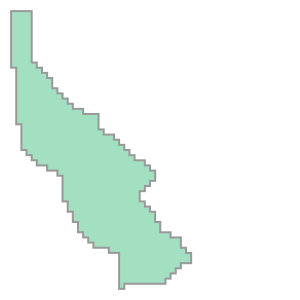

In [67]:
geom1

In [68]:
geom2 = shapely.geometry.shape(h_flows[1454837]['geometry'])

In [69]:
for geom in geom2.geoms:
    geoms.append(geom)

In [76]:
type(geom2.buffer(0))

shapely.geometry.multipolygon.MultiPolygon

In [78]:
geoms

In [72]:
ogeom = shapely.geometry.MultiPolygon(geoms)

In [79]:
for geom in ogeom.geoms:
    print(type(geom))

<class 'shapely.geometry.polygon.Polygon'>
<class 'shapely.geometry.polygon.Polygon'>
<class 'shapely.geometry.polygon.Polygon'>


In [74]:
shapely.geometry.MultiPolygon([ogeom.buffer(0)])

ValueError: Sequences of multi-polygons are not valid arguments

In [82]:
ogeom.buffer(0).geom_type

'MultiPolygon'

In [97]:
shapely.geometry.mapping(ogeom)

{'type': 'MultiPolygon',
 'coordinates': [(((-6735.000038776477, 986624.999953425),
    (-6734.999966409307, 986804.9999726986),
    (-6734.999953823774, 986834.9999705878),
    (-6795.000008437146, 986835.0000189989),
    (-6794.9999825811165, 986865.0000314058),
    (-6884.999998998524, 986865.0000234395),
    (-6884.999953314685, 986895.0000504393),
    (-6915.000015289351, 986895.0000263718),
    (-6914.999962975121, 986924.9999564022),
    (-6945.000018473437, 986925.0000330444),
    (-6944.999959435673, 986954.9999775388),
    (-6975.000008542328, 986955.00004348),
    (-6974.999970944664, 987014.9999758408),
    (-7005.000007106102, 987015.0000311503),
    (-7004.999955724225, 987075.0000212056),
    (-7034.999979022578, 987074.99995447),
    (-7035.000007935655, 987135.0000022835),
    (-7065.000018194063, 987135.0000363239),
    (-7064.999960966859, 987284.9999622885),
    (-7095.000032681501, 987284.9999859651),
    (-7095.00003299711, 987314.9999921137),
    (-7154.999975616